# 03 · NLP baselines: BankSight

**Questions this notebook answers**
1. Can plain TF-IDF text models recognise a complaint's **product** from its narrative? (sanity check that the text is clean and informative)
2. Does the narrative text predict **relief** (`got_relief`) any better than simple, text-free baselines?
3. Which words push a complaint towards relief or towards "closed with explanation"?

**Baseline ladder (all fitted on train, scored on validation; the test period stays sealed)**

| id | model | what it tells us |
|----|-------|------------------|
| B0 | global relief rate | the floor |
| B1 | relief rate by product | the bar every other model must beat |
| B2 | logistic on product + issue | the best "structured" model (notebook 02 showed issue is the only structured signal) |
| B3 | TF-IDF text only | does text alone have signal? |
| B4 | TF-IDF text + product + issue | does text add lift **over** B2? |

Only fixed, untuned settings are used here. Tuning, calibration and thresholds belong to notebook 04, so that this notebook stays an honest "first look".

**What this does:** Loads every library the notebook needs (all imports live in this one cell) and sets how tables are printed.

In [1]:
import time
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             classification_report, f1_score, roc_auc_score)
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4g}".format)

**What this does:** Sets up the folder paths, creates the output folders if missing, and fixes the random seed (so results repeat exactly) and the number of bootstrap rounds used later.

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
REPORT_DIR = ROOT / "reports" / "data_quality"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for folder in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
assert WAREHOUSE.exists(), "Run notebooks 01 and 01b first."
SEED = 42
N_BOOT = 300

## 1. Load train + validation text
Only complaints that have a narrative and a final outcome (`target_eligible`) are used. Test rows are never read.

**What this does:** Opens the database and checks whether the raw table has an `issue` column (some warehouses do not). If it is missing we select `NULL` instead.

In [3]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
column_rows = con.sql(
    "SELECT column_name FROM information_schema.columns WHERE table_schema='raw' AND table_name='cfpb_complaints'").fetchall()
have_cols = set()
for row in column_rows:
    have_cols.add(row[0])
issue_sql = "r.issue" if "issue" in have_cols else "NULL"

**What this does:** Pulls the eligible train and validation complaints (product, issue, relief label, narrative) into one table and closes the database.

In [4]:
df = con.sql(f"""
    SELECT l.complaint_id, l.product_group, l.got_relief, l.split,
           {issue_sql} AS issue, r.narrative
    FROM features.complaint_labels l
    JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible AND l.split IN ('train', 'validation')
      AND r.narrative IS NOT NULL AND length(trim(r.narrative)) > 0
""").df()
con.close()

**What this does:** Makes the label a 0/1 integer, fills missing issues with "Unknown", and splits the table into a train set and a validation set. Then prints their sizes and relief rates.

In [5]:
df["got_relief"] = df["got_relief"].astype(int)
df["issue"] = df["issue"].fillna("Unknown").astype(str)
tr = df[df.split == "train"].reset_index(drop=True)
va = df[df.split == "validation"].reset_index(drop=True)
print(f"train {len(tr):,} | validation {len(va):,} | relief rate train {tr.got_relief.mean():.2%} | validation {va.got_relief.mean():.2%}")
print("\nTop products in train:")
print(tr.product_group.value_counts().head(10).to_string())

train 103,777 | validation 18,537 | relief rate train 23.70% | validation 22.78%

Top products in train:
product_group
Credit reporting                     19614
Credit or prepaid card               16915
Bank account                         16716
Money transfer / virtual currency    15700
Debt collection                      15678
Mortgage                              6837
Student loan                          4464
Vehicle loan or lease                 4393
Payday / personal loan                2772
Debt or credit management              688


## 2. Clean the text
CFPB redacts personal details as `XXXX`, dates as `XX/XX/2024`, and money as `{$1,200.00}`. We map each to a **neutral token** so the
model can still use "an amount was mentioned" without memorising a specific number or a mask pattern.
No stemming or stop-word removal: for linear TF-IDF models it rarely helps and it can hide useful phrases ("not my debt").

**What this does:** Writes down the three search patterns (regular expressions, i.e. text-matching rules) for money amounts, dates and `XXXX` masks. They are kept as plain strings so we can also save them with the model.

In [6]:
PAT_AMOUNT = r"\{\$[\d,\.]+\}|\$\s?[\d,]+(?:\.\d+)?"
PAT_DATE = r"\bXX/XX/(?:XXXX|\d{2,4})\b|\bXX/\d{2}/\d{2,4}\b"
PAT_MASK = r"\bX{2,}\b"

**What this does:** Cleans the narrative column step by step: amounts become ` amtmask `, dates ` datemask `, X-masks ` xmask `, then runs of whitespace are collapsed to one space and the ends are trimmed. The cleaned text goes into a new `text` column for train and validation.

In [7]:
t0 = time.time()
for part in (tr, va):
    text = part.narrative.str.replace(PAT_AMOUNT, " amtmask ", regex=True)
    text = text.str.replace(PAT_DATE, " datemask ", regex=True)
    text = text.str.replace(PAT_MASK, " xmask ", regex=True)
    text = text.str.replace(r"\s+", " ", regex=True)
    part["text"] = text.str.strip()
print(f"cleaned in {time.time() - t0:.1f}s")
print("\nBefore:", tr.narrative.iloc[0][:300])
print("After :", tr.text.iloc[0][:300])

cleaned in 10.2s

Before: The Florida XXXX XXXX Assistance XXXX ( HAF ) approved and have been sending {$430.00} monthly mortgage payments to PNC Bank. According to XXXX from XXXX, on XX/XX/XXXX, XXXX sent PNC bank the mortgage payment that is due XX/XX/XXXX and PNC cashed the funds from XXXX on XX/XX/XXXX. 

Is already XX/X
After : The Florida xmask xmask Assistance xmask ( HAF ) approved and have been sending amtmask monthly mortgage payments to PNC Bank. According to xmask from xmask , on datemask , xmask sent PNC bank the mortgage payment that is due datemask and PNC cashed the funds from xmask on datemask . Is already date


## 3. TF-IDF features
The vectorizer is **fitted on train only**, then applied to validation (fitting on validation would leak its vocabulary and IDF weights).
Unigrams + bigrams, `min_df=5` (drop very rare tokens), `sublinear_tf` (damps repeated words), capped vocabulary to stay inside 8 GB RAM.

**What this does:** Turns each narrative into numbers with TF-IDF (term frequency - inverse document frequency: a word scores high when it is frequent in this complaint but rare across all complaints). We learn the vocabulary on train only and reuse it on validation.

In [8]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True,
                        max_features=150_000, dtype=np.float32)
Xtr_t = tfidf.fit_transform(tr.text)
Xva_t = tfidf.transform(va.text)
print(f"TF-IDF matrix: train {Xtr_t.shape}, validation {Xva_t.shape}, fitted in {time.time() - t0:.0f}s")

TF-IDF matrix: train (103777, 150000), validation (18537, 150000), fitted in 94s


## 4. Task A: can text recognise the product?
A LinearSVC on TF-IDF. This is a routing-style sanity check: if the text could not recognise the product, something would be wrong with the text.
We report **macro-F1** (every product counts equally), because accuracy is dominated by the largest product.

**What this does:** Trains a LinearSVC (a fast linear classifier that draws straight-line boundaries between classes) to guess the product from the text, then predicts on validation. Macro-F1 is the average F1 score (balance of precision and recall) across products, each product counting equally.

In [9]:
t0 = time.time()
svc = LinearSVC(C=0.5, random_state=SEED)
svc.fit(Xtr_t, tr.product_group)
pred = svc.predict(Xva_t)
print(f"fitted in {time.time() - t0:.0f}s")
print(f"accuracy {accuracy_score(va.product_group, pred):.3f} | macro-F1 {f1_score(va.product_group, pred, average='macro'):.3f}"
      f" | majority-class accuracy {(va.product_group == tr.product_group.mode()[0]).mean():.3f}")

fitted in 32s
accuracy 0.804 | macro-F1 0.742 | majority-class accuracy 0.217


**What this does:** Builds a per-product report (precision, recall, F1) from the predictions, shows it, and saves it as a CSV.

In [10]:
rep = pd.DataFrame(classification_report(va.product_group, pred, output_dict=True, zero_division=0)).T
rep = rep.drop(index=["accuracy"], errors="ignore")
display(rep.round(3))
rep.to_csv(REPORT_DIR / "03_product_classifier_validation.csv")

,precision,recall,f1-score,support
Bank account,0.772,0.825,0.798,"2,820"
Credit or prepaid card,0.789,0.736,0.762,"2,930"
Credit reporting,0.781,0.899,0.836,"4,016"
Debt collection,0.841,0.82,0.83,"3,754"
Debt or credit management,0.897,0.149,0.255,175
Money transfer / virtual currency,0.777,0.749,0.763,"1,748"
Mortgage,0.931,0.908,0.919,"1,062"
Payday / personal loan,0.753,0.528,0.621,653
Student loan,0.859,0.812,0.835,451
Vehicle loan or lease,0.834,0.782,0.807,928


## 5. Task B: relief baselines B0 to B4
`PR-AUC` is the headline (the relief class is the minority and ranking matters); ROC-AUC and Brier are shown too.
**Within-product ROC-AUC** is the honest test: a model can look good overall just by knowing which products get relief more often.
Rows are the *same* validation complaints for every model, so differences are paired.

**What this does:** Builds the two simplest baselines. B0 gives every complaint the overall relief rate from train. B1 gives each complaint the relief rate of its product (unseen products fall back to the overall rate).

In [11]:
y_tr = tr.got_relief.to_numpy()
y_va = va.got_relief.to_numpy()
base_rate = float(y_tr.mean())

p0 = np.full(len(va), base_rate)
product_rate = tr.groupby("product_group").got_relief.mean()
p1 = va.product_group.map(product_rate).fillna(base_rate).to_numpy()

**What this does:** One-hot encodes product and issue (one 0/1 column per category; categories with fewer than 20 rows are pooled into an "other" column). This is the structured input for B2 and B4.

In [12]:
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=True, dtype=np.float32)
Xtr_s = ohe.fit_transform(tr[["product_group", "issue"]])
Xva_s = ohe.transform(va[["product_group", "issue"]])

**What this does:** Fits B2, a logistic regression (a simple model that turns features into a probability between 0 and 1) on product + issue only, and predicts relief probabilities for validation.

In [13]:
t0 = time.time()
m2 = LogisticRegression(C=1.0, solver="liblinear", max_iter=200, random_state=SEED)
m2.fit(Xtr_s, y_tr)
p2 = m2.predict_proba(Xva_s)[:, 1]
print(f"B2 fitted in {time.time() - t0:.0f}s")

B2 fitted in 1s


**What this does:** Fits B3, the same kind of logistic regression but on the TF-IDF text only.

In [14]:
t0 = time.time()
m3 = LogisticRegression(C=1.0, solver="liblinear", max_iter=200, random_state=SEED)
m3.fit(Xtr_t, y_tr)
p3 = m3.predict_proba(Xva_t)[:, 1]
print(f"B3 fitted in {time.time() - t0:.0f}s")

B3 fitted in 26s


**What this does:** Fits B4: glues the text columns and the product/issue columns side by side and fits the same logistic regression on both.

In [15]:
t0 = time.time()
Xtr_c = sp.hstack([Xtr_t, Xtr_s]).tocsr()
Xva_c = sp.hstack([Xva_t, Xva_s]).tocsr()
m4 = LogisticRegression(C=1.0, solver="liblinear", max_iter=200, random_state=SEED)
m4.fit(Xtr_c, y_tr)
p4 = m4.predict_proba(Xva_c)[:, 1]
print(f"B4 fitted in {time.time() - t0:.0f}s")

B4 fitted in 79s


**What this does:** Collects all five sets of predictions in one dictionary so the next cells can loop over them.

In [16]:
preds = {"B0 global rate": p0, "B1 product rate": p1, "B2 product+issue": p2,
         "B3 text only": p3, "B4 text+product+issue": p4}

**What this does:** Scores every model on validation with four numbers. PR-AUC is the area under the precision-recall curve (how well true relief cases are ranked near the top; random = relief rate). ROC-AUC is the chance that a random relief case is ranked above a random non-relief case (0.5 = coin flip). Brier score is the mean squared error of the probabilities (lower is better). Within-product AUC is the ROC-AUC computed separately inside each product (products with at least 100 rows and both outcomes) and averaged, weighted by size; it shows whether the model ranks well beyond just knowing the product.

In [17]:
products_va = va.product_group.to_numpy()
rows = []
for name in preds:
    p = preds[name]
    has_spread = np.ptp(p) > 0  # a constant prediction cannot rank anything

    aucs = []
    sizes = []
    for product in sorted(set(products_va)):
        idx = np.where(products_va == product)[0]
        n_relief = y_va[idx].sum()
        if len(idx) >= 100 and 0 < n_relief < len(idx):
            aucs.append(roc_auc_score(y_va[idx], p[idx]))
            sizes.append(len(idx))
    within_auc = float(np.average(aucs, weights=sizes)) if aucs else np.nan

    rows.append({"model": name,
                 "pr_auc": average_precision_score(y_va, p),
                 "roc_auc": roc_auc_score(y_va, p) if has_spread else 0.5,
                 "within_product_roc_auc": within_auc if has_spread else 0.5,
                 "brier": brier_score_loss(y_va, np.clip(p, 1e-6, 1 - 1e-6))})

**What this does:** Turns the scores into a table, prints it next to the validation relief rate, and saves it as a CSV.

In [18]:
res = pd.DataFrame(rows).set_index("model")
print(f"validation relief rate (= PR-AUC of a random model): {y_va.mean():.3f}")
display(res)
res.to_csv(REPORT_DIR / "03_relief_baselines_validation.csv")

validation relief rate (= PR-AUC of a random model): 0.228


,pr_auc,roc_auc,within_product_roc_auc,brier
model,,,,
B0 global rate,0.2278,0.5,0.5,0.176
B1 product rate,0.3451,0.6916,0.5,0.1643
B2 product+issue,0.354,0.6976,0.5362,0.1637
B3 text only,0.4213,0.7439,0.6691,0.1577
B4 text+product+issue,0.4275,0.7519,0.6777,0.1565


## 6. Is the lift real? Paired bootstrap
We resample validation complaints with replacement 300 times and recompute the *difference* in PR-AUC and ROC-AUC between pairs of models.
If the 95% interval excludes 0, the difference is unlikely to be sampling noise. Intervals still reflect only one validation period; the
complaints are also not fully independent (the same issue wave can hit many consumers), so treat them as optimistic.

**What this does:** Runs the paired bootstrap. A bootstrap redraws the validation complaints at random with replacement, many times; "paired" means both models of a comparison are scored on the very same redrawn rows. Each round we store the difference (second model minus first) in PR-AUC and ROC-AUC for every pair.

In [19]:
rng = np.random.default_rng(SEED)
n_val = len(y_va)
pairs = [("B1 product rate", "B2 product+issue"), ("B1 product rate", "B3 text only"),
         ("B1 product rate", "B4 text+product+issue"), ("B2 product+issue", "B4 text+product+issue")]
models_in_pairs = ["B1 product rate", "B2 product+issue", "B3 text only", "B4 text+product+issue"]

pr_diffs = {}
roc_diffs = {}
for pair in pairs:
    pr_diffs[pair] = []
    roc_diffs[pair] = []

for round_number in range(N_BOOT):
    idx = rng.integers(0, n_val, n_val)
    y_boot = y_va[idx]
    if y_boot.min() == y_boot.max():
        continue  # need both outcomes to score AUC

    pr_scores = {}
    roc_scores = {}
    for name in models_in_pairs:
        p_boot = preds[name][idx]
        pr_scores[name] = average_precision_score(y_boot, p_boot)
        roc_scores[name] = roc_auc_score(y_boot, p_boot) if np.ptp(p_boot) > 0 else 0.5

    for pair in pairs:
        first, second = pair
        pr_diffs[pair].append(pr_scores[second] - pr_scores[first])
        roc_diffs[pair].append(roc_scores[second] - roc_scores[first])

**What this does:** Summarises each pair: the mean difference and the 95% interval (2.5th to 97.5th percentile of the 300 differences), and flags whether the interval stays on one side of 0.

In [20]:
out = []
for pair in pairs:
    first, second = pair
    for metric, diffs in (("pr_auc", pr_diffs[pair]), ("roc_auc", roc_diffs[pair])):
        v = np.array(diffs)
        low = np.percentile(v, 2.5)
        high = np.percentile(v, 97.5)
        out.append({"comparison": f"{second}  minus  {first}", "metric": metric, "diff": v.mean(),
                    "ci_low": low, "ci_high": high, "ci_excludes_0": bool(low > 0 or high < 0)})
boot_df = pd.DataFrame(out)
display(boot_df)
boot_df.to_csv(REPORT_DIR / "03_paired_bootstrap.csv", index=False)

,comparison,metric,diff,ci_low,ci_high,ci_excludes_0
0,B2 product+issue minus B1 product rate,pr_auc,0.009042,0.004971,0.01296,True
1,B2 product+issue minus B1 product rate,roc_auc,0.005814,0.002359,0.00869,True
2,B3 text only minus B1 product rate,pr_auc,0.07606,0.06508,0.08737,True
3,B3 text only minus B1 product rate,roc_auc,0.05158,0.04293,0.05941,True
4,B4 text+product+issue minus B1 product rate,pr_auc,0.08234,0.07223,0.0933,True
5,B4 text+product+issue minus B1 product rate,roc_auc,0.05977,0.05357,0.06563,True
6,B4 text+product+issue minus B2 product+issue,pr_auc,0.0733,0.06119,0.08486,True
7,B4 text+product+issue minus B2 product+issue,roc_auc,0.05395,0.04776,0.05943,True


## 7. Which words move the relief odds?
Coefficients of B3 (text only). A positive coefficient pushes towards relief. These are **associations in the text**, not causes, and some words
are simply proxies for a product or an issue (see B4 for the effect after controlling those).

**What this does:** Reads the B3 model's coefficients (one weight per word or word pair; positive pushes towards relief, negative towards "closed with explanation"). It lists the 25 strongest words each way and saves them to a CSV.

In [21]:
terms = np.array(tfidf.get_feature_names_out())
coef = m3.coef_[0]
order = np.argsort(coef)
top_pos = pd.DataFrame({"term": terms[order[::-1][:25]], "coef": coef[order[::-1][:25]]})
top_neg = pd.DataFrame({"term": terms[order[:25]], "coef": coef[order[:25]]})
print("Towards RELIEF")
display(top_pos.T)
print("Towards CLOSED WITH EXPLANATION")
display(top_neg.T)
both = pd.concat([top_pos.assign(direction="relief"), top_neg.assign(direction="explanation")])
both.to_csv(REPORT_DIR / "03_top_terms_text_only.csv", index=False)

Towards RELIEF


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
term,transunion,citi,comenity,credence,citibank,venmo,midland,credence resource,resource,td,credit,resource management,accounts,late,of america,comenity bank,portfolio recovery,card,boa,bank of,huntington,us bank,direct express,amex,trans union
coef,9.811,5.154,4.989,4.925,4.428,4.033,3.923,3.509,3.336,3.157,3.144,2.844,2.832,2.797,2.796,2.691,2.664,2.634,2.633,2.619,2.617,2.573,2.568,2.547,2.521


Towards CLOSED WITH EXPLANATION


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
term,experian,cash app,loan,mortgage,zelle,cashapp,app,nelnet,affirm,inc,loans,cash,robinhood,was,finance,jefferson,systems,vanilla,barclays,jefferson capital,financial,funds,money,netspend,foreclosure
coef,-6.878,-5.309,-4.937,-4.918,-4.77,-4.507,-4.201,-3.603,-3.601,-3.324,-2.995,-2.98,-2.942,-2.932,-2.823,-2.695,-2.692,-2.636,-2.481,-2.448,-2.342,-2.305,-2.268,-2.124,-2.118


**What this does:** Draws the 15 strongest words in each direction as two bar charts side by side and saves the picture.

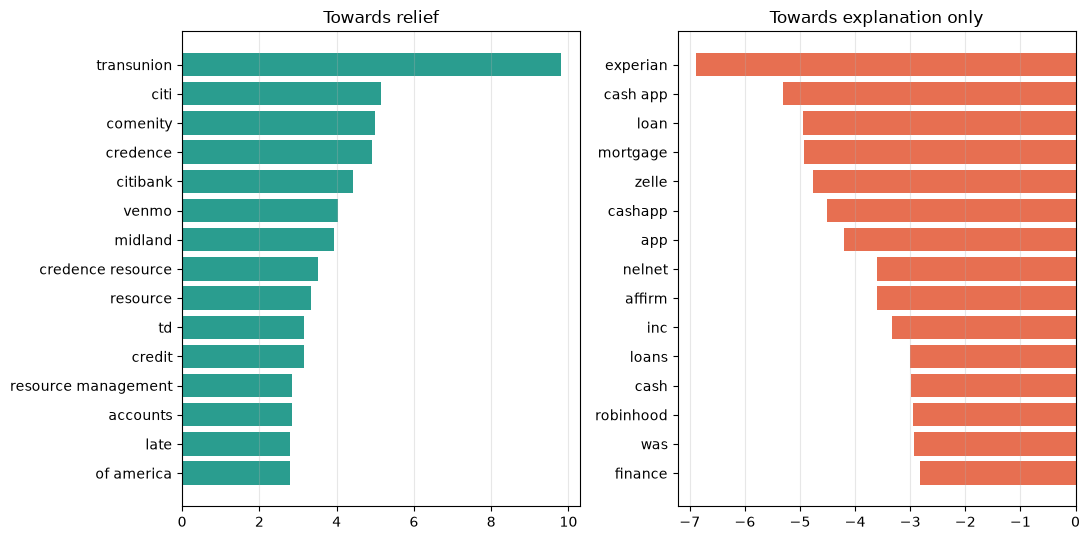

In [22]:
pos15 = top_pos.head(15)[::-1]
neg15 = top_neg.head(15)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5), sharex=False)
ax[0].barh(pos15.term, pos15.coef, color="#2a9d8f")
ax[0].set_title("Towards relief")
ax[0].grid(axis="x", alpha=.3)
ax[1].barh(neg15.term, neg15.coef, color="#e76f51")
ax[1].set_title("Towards explanation only")
ax[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_top_terms.png", dpi=140)
plt.show()

## 8. Issue taxonomy coverage
How concentrated are the issue labels? This decides whether a small, fixed issue list is enough or whether we need to group or cluster the text
(notebook later on).

**What this does:** Counts complaints per issue in train, and computes each issue's share and the running (cumulative) share, so we can see how few issues cover most complaints. Saves the table.

In [23]:
issue_counts = tr.issue.value_counts()
cov = pd.DataFrame({"n": issue_counts, "share": issue_counts / issue_counts.sum(),
                    "cum_share": (issue_counts / issue_counts.sum()).cumsum()})
print(f"distinct issues in train: {len(issue_counts)}")
display(cov.head(15))
for k in (5, 10, 20):
    print(f"top {k:>2} issues cover {cov.cum_share.iloc[min(k, len(cov)) - 1]:.1%} of train complaints")
cov.to_csv(REPORT_DIR / "03_issue_coverage.csv")

distinct issues in train: 88


,n,share,cum_share
issue,,,
Incorrect information on your report,10782,0.1039,0.1039
Other transaction problem,10025,0.0966,0.2005
Managing an account,8814,0.08493,0.2854
Attempts to collect debt not owed,7271,0.07006,0.3555
Improper use of your report,5994,0.05776,0.4133
Problem with a company's investigation into an existing problem,5292,0.05099,0.4642
Written notification about debt,4083,0.03934,0.5036
Trouble during payment process,3769,0.03632,0.5399
Problem with a purchase shown on your statement,3617,0.03485,0.5748


top  5 issues cover 41.3% of train complaints
top 10 issues cover 60.5% of train complaints
top 20 issues cover 78.6% of train complaints


## 9. Save the artefacts
The vectorizer and the B4 model are saved for notebook 04 and for later error analysis. The data itself is not saved here.

**What this does:** Saves the TF-IDF vectorizer, the one-hot encoder, the B4 model and the cleaning patterns into one compressed file for notebook 04, then lists the report files written.

In [24]:
bundle = {"tfidf": tfidf, "ohe": ohe, "model": m4,
          "clean_patterns": [PAT_AMOUNT, PAT_DATE, PAT_MASK]}
joblib.dump(bundle, MODEL_DIR / "03_tfidf_relief_B4.joblib", compress=3)
print("saved:", MODEL_DIR / "03_tfidf_relief_B4.joblib")
print("reports:", *sorted(p.name for p in REPORT_DIR.glob("03_*")), sep="\n  ")

saved: ..\models\03_tfidf_relief_B4.joblib
reports:
  03_issue_coverage.csv
  03_paired_bootstrap.csv
  03_product_classifier_validation.csv
  03_relief_baselines_validation.csv
  03_top_terms_text_only.csv
